# Gasto público en políticas activas de empleo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "gasto-politicas-activas"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en políticas activas de empleo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El gasto público en políticas activas del mercado de trabajo en porcentaje del PIB: servicios públicos de empleo y su administración, formación, incentivos a la contratación, empleo protegido y con apoyo, creación directa de empleo e incentivos al autoempleo (categorías 1 a 7 de la base de datos de políticas del mercado de trabajo, común a la OCDE y a la Comisión Europea).

**Cómo se lee.** Un valor de 0,5 significa que el gasto equivale a medio punto del PIB. No incluye las prestaciones por desempleo ni la jubilación anticipada (políticas pasivas, categorías 8 y 9), que el notebook calcula aparte para las notas.

**Limitaciones.**
- El gasto en porcentaje del PIB depende de cuánto paro hay: con más parados suele subir aunque no cambie el gasto por persona.
- Los países clasifican sus programas en las categorías con criterios que no son del todo iguales; los programas extraordinarios de 2020 y 2021 se recogen en la categoría que cada país les asignó.
- No incluye el gasto en formación de las empresas ni el de las administraciones que no se declara a la base de datos.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, *Labour Market Programmes* (`OECD.ELS.JAI,DSD_LMP@DF_LMP`, versión 1.0): gasto público (`EXP`) en las categorías 1 a 7 (`LMP_10T70`), en % del PIB (`PT_B1GQ`). El config no fijaba el dataflow («a identificar en el Data Explorer»).
- **UE-27:** sin dato. La OCDE no publica el agregado de la UE-27 en este dataflow y Eurostat ya no difunde `lmp_expsumm` (la base de datos de la UE la publica ahora la Comisión Europea fuera de Eurostat; anotado en `pending.md`).
- **Solo para las notas:** el gasto en políticas pasivas (`LMP_80_90`, categorías 8 y 9).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

HOY = date.today().isoformat()
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde", "EU27_2020": "ue27"}
DATAFLOW = "OECD.ELS.JAI,DSD_LMP@DF_LMP,1.0"
# Dimensiones: país . medida (EXP: gasto) . programa (LMP_10T70: categorías 1 a 7) . unidad (PT_B1GQ: % del PIB)
CLAVE = "{AREA}.EXP.LMP_10T70.PT_B1GQ"

oc, fuentes_oc = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
pasivas, _ = oecd.get(DATAFLOW, "{AREA}.EXP.LMP_80_90.PT_B1GQ", areas=AREAS, desde=DESDE)  # solo para las notas
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))

         min   max  count
serie                    
canada  1985  2024     40
eeuu    1985  2024     40
espana  1985  2024     40
ocde    2004  2024     21


## 3. Transformación

1. Las series se usan tal como las publica la OCDE, en % del PIB.
2. La UE-27 queda sin dato, con la fuente consultada.
3. **Políticas pasivas** del último año, para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


SIN = (oecd.ORGANISMO, "DSD_LMP@DF_LMP: la OCDE no publica el agregado de la UE-27; Eurostat ya no difunde lmp_expsumm",
       oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(oc, fuentes_oc, {s: SIN for s in ["ue27"] if s not in set(oc["serie"])})
assert df["valor"].dropna().between(0, 10).all(), "porcentaje del PIB fuera de rango"

ULTIMO = int(serie(pasivas, "espana").index.max())
NOTAS = [
    "OCDE, programas del mercado de trabajo (DSD_LMP@DF_LMP): gasto público en las categorías 1 a 7 (servicios "
    "públicos de empleo y administración, formación, incentivos al empleo, empleo protegido y con apoyo, creación "
    "directa de empleo e incentivos al autoempleo), en % del PIB.",
    f"Políticas pasivas (categorías 8 y 9: prestaciones por desempleo y jubilación anticipada), en {ULTIMO}: "
    f"{es(serie(pasivas, 'espana')[ULTIMO], 2)} % del PIB en España"
    + (f" y {es(serie(pasivas, 'ocde')[ULTIMO], 2)} % en la OCDE" if ULTIMO in serie(pasivas, "ocde").index else "")
    + ". El gasto en % del PIB sube cuando hay más paro, aunque no cambie el gasto por persona.",
    "Los programas extraordinarios de 2020 y 2021 se recogen en la categoría que cada país les asignó al declararlos a "
    "la base de datos; las variaciones de esos años dependen de esa clasificación.",
    "UE-27: la OCDE no publica el agregado en este dataflow y Eurostat ya no difunde la base de datos de políticas del "
    "mercado de trabajo; la serie queda vacía.",
]
for n in NOTAS:
    print("-", n)
display(df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").tail(8))

- OCDE, programas del mercado de trabajo (DSD_LMP@DF_LMP): gasto público en las categorías 1 a 7 (servicios públicos de empleo y administración, formación, incentivos al empleo, empleo protegido y con apoyo, creación directa de empleo e incentivos al autoempleo), en % del PIB.
- Políticas pasivas (categorías 8 y 9: prestaciones por desempleo y jubilación anticipada), en 2024: 1,64 % del PIB en España y 0,56 % en la OCDE. El gasto en % del PIB sube cuando hay más paro, aunque no cambie el gasto por persona.
- Los programas extraordinarios de 2020 y 2021 se recogen en la categoría que cada país les asignó al declararlos a la base de datos; las variaciones de esos años dependen de esa clasificación.
- UE-27: la OCDE no publica el agregado en este dataflow y Eurostat ya no difunde la base de datos de políticas del mercado de trabajo; la serie queda vacía.


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2017,0.224,0.101,0.685,0.472,NaN
2018,0.209,0.101,0.702,0.430,NaN
2019,0.405,2.560,0.689,0.629,NaN
2020,3.710,1.350,1.180,0.795,NaN
2021,0.910,0.078,0.922,0.620,NaN
2022,0.209,0.078,0.745,0.419,NaN
2023,0.194,0.075,0.688,0.393,NaN
2024,0.170,0.064,0.642,0.386,NaN


## 4. Visualización

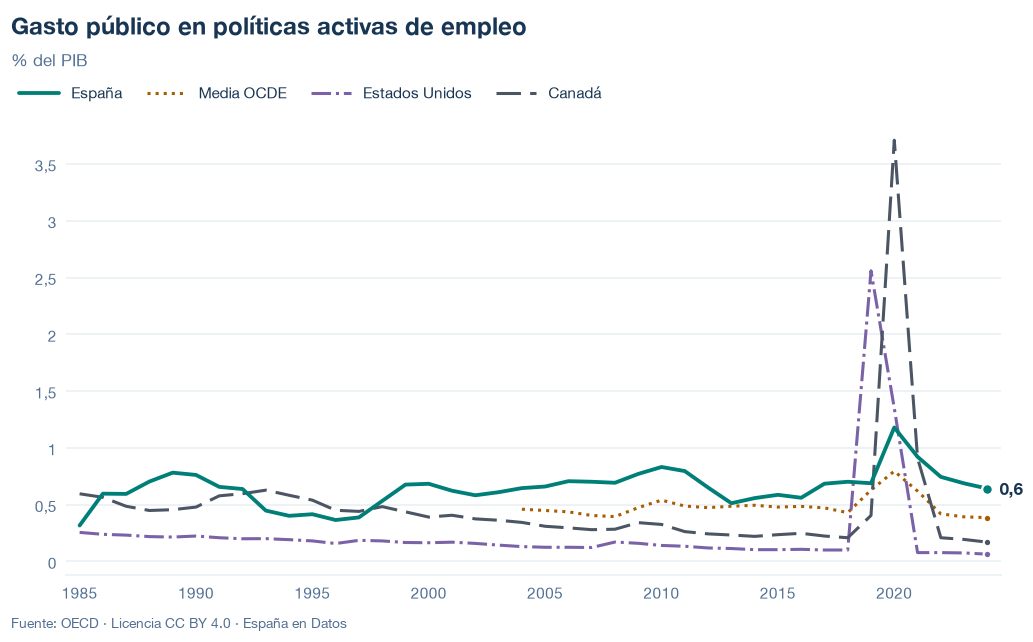

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-politicas-activas.json y data/gasto-politicas-activas.csv


## 6. Fuentes, notas y licencia

- OCDE, programas del mercado de trabajo: `OECD.ELS.JAI,DSD_LMP@DF_LMP,1.0` (`EXP`, `LMP_10T70`, `PT_B1GQ`; `LMP_80_90` solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.